In [ ]:
# ============================================================
# COMP9417 Air Quality Project
# STEP 8 – CLASSIFICATION MODELLING (CO Level Prediction)
# ============================================================
# Models used:
#   - Logistic Regression
#   - Random Forest Classifier
#   - XGBoost Classifier
#
# Target:
#   CO(GT) discretised into 3 classes (low / mid / high), (labels = 0,1,2)
#
# Forecast horizons:
#   1h, 6h, 12h, 24h ahead
# ============================================================



import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load CSV
df = pd.read_csv("./AirQualityUCI.csv", sep=";")

In [2]:
# Replace comma decimal separators if present
df = df.replace(",", ".", regex=True)

# Convert all numeric columns to float
for col in df.columns:
    try:
        df[col] = pd.to_numeric(df[col])
    except:
        pass

# Replace -200 with NaN
df = df.replace(-200, np.nan)

print(df.isna().mean().sort_values(ascending=False))


Unnamed: 16      1.000000
Unnamed: 15      1.000000
NMHC(GT)         0.903495
CO(GT)           0.189737
NO2(GT)          0.185408
NOx(GT)          0.185091
PT08.S5(O3)      0.050681
AH               0.050681
RH               0.050681
T                0.050681
PT08.S3(NOx)     0.050681
PT08.S4(NO2)     0.050681
PT08.S2(NMHC)    0.050681
C6H6(GT)         0.050681
PT08.S1(CO)      0.050681
Time             0.012037
Date             0.012037
dtype: float64


In [3]:
# --- FIX TIME FORMAT (dot → colon) ---
df['Time'] = df['Time'].astype(str).str.replace('.', ':', regex=False)

# --- CREATE TIMESTAMP ---
df['timestamp'] = pd.to_datetime(
    df['Date'] + " " + df['Time'], 
    dayfirst=True,
    errors='coerce'
)

# --- DROP BAD ROWS ---
df = df.dropna(subset=['timestamp'])
df = df.sort_values('timestamp')
df = df.set_index('timestamp')

# Remove old columns
df = df.drop(columns=['Date', 'Time'])


In [4]:
df["hour"] = df.index.hour
df["weekday"] = df.index.weekday
df["month"] = df.index.month


In [5]:
TARGETS = ['CO(GT)', 'NMHC(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']

horizons = [1, 6, 12, 24]  # hours ahead

for h in horizons:
    df[f"CO_t+{h}"] = df["CO(GT)"].shift(-h)
    df[f"NO2_t+{h}"] = df["NO2(GT)"].shift(-h)
    df[f"NOx_t+{h}"] = df["NOx(GT)"].shift(-h)
    df[f"C6H6_t+{h}"] = df["C6H6(GT)"].shift(-h)
    df[f"NMHC_t+{h}"] = df["NMHC(GT)"].shift(-h)
    
def co_class(x):
    if x < 1.5:
        return 0
    elif x < 2.5:
        return 1
    else:
        return 2

for h in horizons:
    df[f"CO_class_t+{h}"] = df[f"CO_t+{h}"].apply(co_class)
    
df = df.ffill().bfill()
df = df.drop(columns=["Unnamed: 15", "Unnamed: 16"], errors='ignore')


In [6]:
train = df[:'2004-12-31']
test  = df['2005-01-01':]

val_size = int(len(train) * 0.1)
val = train[-val_size:]
train = train[:-val_size]

print("Train:", train.shape)
print("Val:", val.shape)
print("Test:", test.shape)


Train: (6399, 40)
Val: (711, 40)
Test: (2247, 40)


In [7]:
train

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),...,NMHC_t+12,CO_t+24,NO2_t+24,NOx_t+24,C6H6_t+24,NMHC_t+24,CO_class_t+1,CO_class_t+6,CO_class_t+12,CO_class_t+24
timestamp,,,,,,,,,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,...,16.0,4.8,151.0,281.0,20.8,307.0,1,0,0,2
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,...,29.0,6.9,172.0,383.0,27.4,461.0,1,0,0,2
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,...,64.0,6.1,165.0,351.0,24.0,401.0,1,0,1,2
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,...,87.0,3.9,136.0,240.0,12.8,197.0,1,0,1,2
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,...,77.0,1.5,85.0,94.0,4.7,61.0,0,2,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2004-12-02 04:00:00,0.9,889.0,275.0,2.9,646.0,131.0,2047.0,70.0,1163.0,743.0,...,275.0,1.1,80.0,133.0,3.8,275.0,0,2,2,0
2004-12-02 05:00:00,0.7,880.0,275.0,2.4,610.0,101.0,2095.0,59.0,1150.0,711.0,...,275.0,0.7,74.0,103.0,2.5,275.0,0,2,2,0
2004-12-02 06:00:00,0.9,919.0,275.0,4.0,711.0,189.0,1667.0,74.0,1195.0,819.0,...,275.0,0.9,82.0,178.0,4.0,275.0,0,2,2,0


In [8]:
from sklearn.preprocessing import StandardScaler

# Select columns to scale (exclude future targets)
feature_cols = [c for c in train.columns if "_t+" not in c]

scaler = StandardScaler()

train_scaled = pd.DataFrame(
    scaler.fit_transform(train[feature_cols]),
    index=train.index,
    columns=feature_cols
)

val_scaled = pd.DataFrame(
    scaler.transform(val[feature_cols]),
    index=val.index,
    columns=feature_cols
)

test_scaled = pd.DataFrame(
    scaler.transform(test[feature_cols]),
    index=test.index,
    columns=feature_cols
)


In [9]:
feature_cols = [c for c in train.columns if "_class_t+" not in c]


CONFUSION MATRIX & REPORT — CO Classification t+1


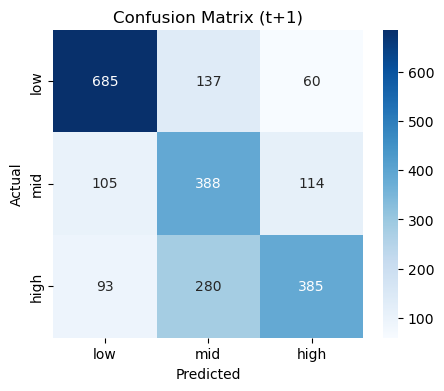

              precision    recall  f1-score   support

         low       0.78      0.78      0.78       882
         mid       0.48      0.64      0.55       607
        high       0.69      0.51      0.58       758

    accuracy                           0.65      2247
   macro avg       0.65      0.64      0.64      2247
weighted avg       0.67      0.65      0.65      2247

CONFUSION MATRIX & REPORT — CO Classification t+6


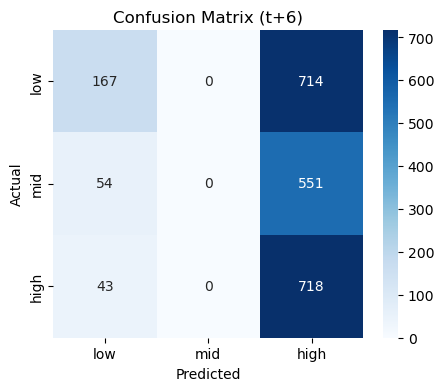

              precision    recall  f1-score   support

         low       0.63      0.19      0.29       881
         mid       0.00      0.00      0.00       605
        high       0.36      0.94      0.52       761

    accuracy                           0.39      2247
   macro avg       0.33      0.38      0.27      2247
weighted avg       0.37      0.39      0.29      2247

CONFUSION MATRIX & REPORT — CO Classification t+12


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


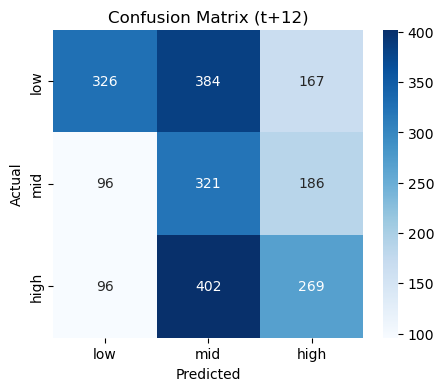

              precision    recall  f1-score   support

         low       0.63      0.37      0.47       877
         mid       0.29      0.53      0.38       603
        high       0.43      0.35      0.39       767

    accuracy                           0.41      2247
   macro avg       0.45      0.42      0.41      2247
weighted avg       0.47      0.41      0.42      2247

CONFUSION MATRIX & REPORT — CO Classification t+24


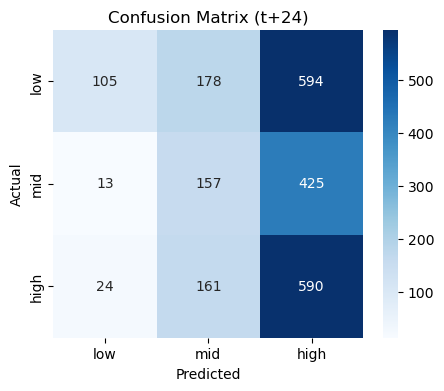

              precision    recall  f1-score   support

         low       0.74      0.12      0.21       877
         mid       0.32      0.26      0.29       595
        high       0.37      0.76      0.49       775

    accuracy                           0.38      2247
   macro avg       0.47      0.38      0.33      2247
weighted avg       0.50      0.38      0.33      2247



In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

horizons = [1, 6, 12, 24]

for h in horizons:
    print(f"CONFUSION MATRIX & REPORT — CO Classification t+{h}")

    # ----------- 1. Feature matrices -----------
    X_train = train_scaled
    X_test  = test_scaled


    # ----------- 2. Classification targets -----------
    y_train = train[f"CO_class_t+{h}"]
    y_test  = test[f"CO_class_t+{h}"]


    # ----------- 3. Train Logistic Regression -----------
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)


    # ----------- 4. Predictions -----------
    pred = model.predict(X_test)


    # ----------- 5. Confusion Matrix -----------
    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["low", "mid", "high"],
                yticklabels=["low", "mid", "high"])
    plt.title(f"Confusion Matrix (t+{h})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


    # ----------- 6. Classification Report -----------
    print(classification_report(
        y_test, pred,
        target_names=["low", "mid", "high"]
    ))


----------- XGBOOST CLASSIFICATION RESULTS -----------

>>> CO Classification (t+1)

Accuracy (t+1): 0.7267


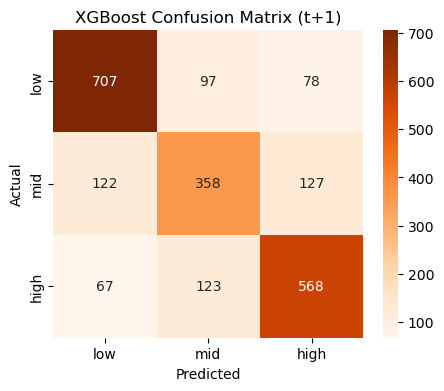

              precision    recall  f1-score   support

         low       0.79      0.80      0.80       882
         mid       0.62      0.59      0.60       607
        high       0.73      0.75      0.74       758

    accuracy                           0.73      2247
   macro avg       0.71      0.71      0.71      2247
weighted avg       0.72      0.73      0.73      2247


>>> CO Classification (t+6)

Accuracy (t+6): 0.5563


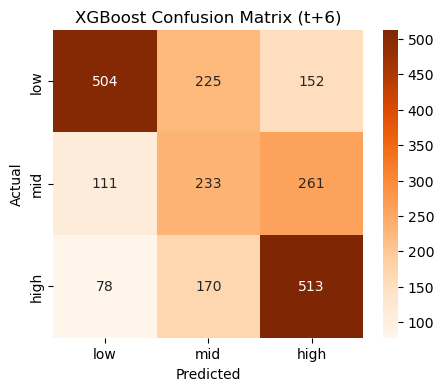

              precision    recall  f1-score   support

         low       0.73      0.57      0.64       881
         mid       0.37      0.39      0.38       605
        high       0.55      0.67      0.61       761

    accuracy                           0.56      2247
   macro avg       0.55      0.54      0.54      2247
weighted avg       0.57      0.56      0.56      2247


>>> CO Classification (t+12)

Accuracy (t+12): 0.5278


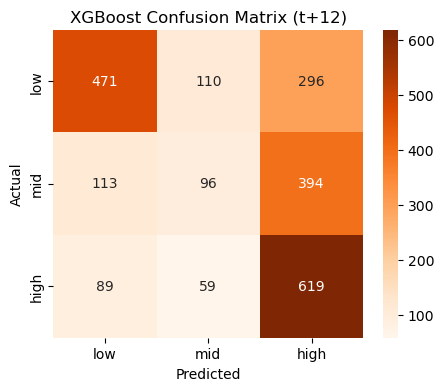

              precision    recall  f1-score   support

         low       0.70      0.54      0.61       877
         mid       0.36      0.16      0.22       603
        high       0.47      0.81      0.60       767

    accuracy                           0.53      2247
   macro avg       0.51      0.50      0.48      2247
weighted avg       0.53      0.53      0.50      2247


>>> CO Classification (t+24)

Accuracy (t+24): 0.5683


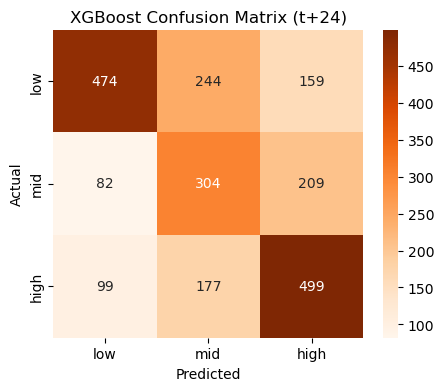

              precision    recall  f1-score   support

         low       0.72      0.54      0.62       877
         mid       0.42      0.51      0.46       595
        high       0.58      0.64      0.61       775

    accuracy                           0.57      2247
   macro avg       0.57      0.57      0.56      2247
weighted avg       0.59      0.57      0.57      2247



In [11]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

horizons = [1, 6, 12, 24]

print("----------- XGBOOST CLASSIFICATION RESULTS -----------")

for h in horizons:
    print(f"\n>>> CO Classification (t+{h})\n")

    # ----------- 1. Feature matrices -----------
    X_train = train_scaled
    X_test  = test_scaled


    # ----------- 2. Classification targets -----------
    y_train = train[f"CO_class_t+{h}"]
    y_test  = test[f"CO_class_t+{h}"]
    

    # ----------- 3. XGBoost Classifier -----------
    model = xgb.XGBClassifier(
        objective='multi:softmax',
        num_class=3,
        eval_metric='mlogloss',
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    # ----------- 4. Train -----------
    model.fit(X_train, y_train)


    # ----------- 5. Predict -----------
    pred = model.predict(X_test)


    # ----------- 6. Accuracy -----------
    acc = accuracy_score(y_test, pred)
    print(f"Accuracy (t+{h}): {acc:.4f}")


    # ----------- 7. Confusion Matrix -----------
    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
                xticklabels=["low", "mid", "high"],
                yticklabels=["low", "mid", "high"])
    plt.title(f"XGBoost Confusion Matrix (t+{h})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # ----------- 8. Classification Report -----------
    print(classification_report(
        y_test, pred,
        target_names=["low", "mid", "high"]
    ))


----------- RANDOM FOREST CLASSIFICATION RESULTS -----------

>>> CO Classification (t+1)

Accuracy (t+1): 0.7045


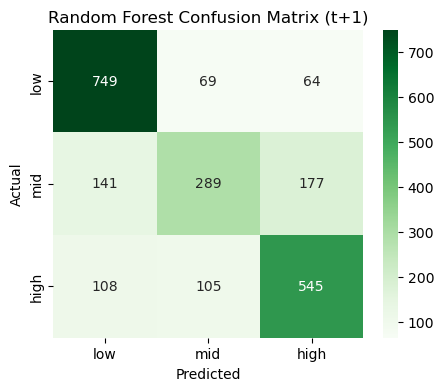

              precision    recall  f1-score   support

         low       0.75      0.85      0.80       882
         mid       0.62      0.48      0.54       607
        high       0.69      0.72      0.71       758

    accuracy                           0.70      2247
   macro avg       0.69      0.68      0.68      2247
weighted avg       0.70      0.70      0.70      2247


>>> CO Classification (t+6)

Accuracy (t+6): 0.5478


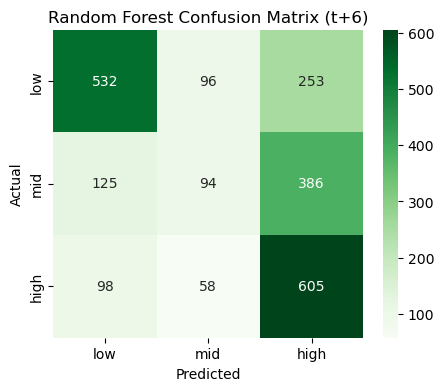

              precision    recall  f1-score   support

         low       0.70      0.60      0.65       881
         mid       0.38      0.16      0.22       605
        high       0.49      0.80      0.60       761

    accuracy                           0.55      2247
   macro avg       0.52      0.52      0.49      2247
weighted avg       0.54      0.55      0.52      2247


>>> CO Classification (t+12)

Accuracy (t+12): 0.5060


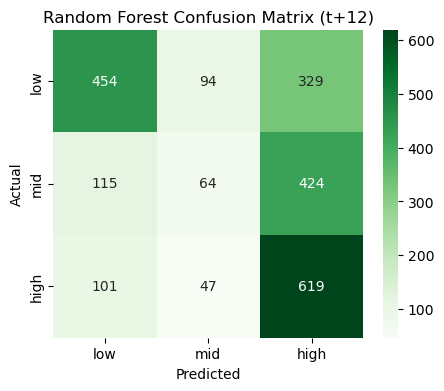

              precision    recall  f1-score   support

         low       0.68      0.52      0.59       877
         mid       0.31      0.11      0.16       603
        high       0.45      0.81      0.58       767

    accuracy                           0.51      2247
   macro avg       0.48      0.48      0.44      2247
weighted avg       0.50      0.51      0.47      2247


>>> CO Classification (t+24)

Accuracy (t+24): 0.5314


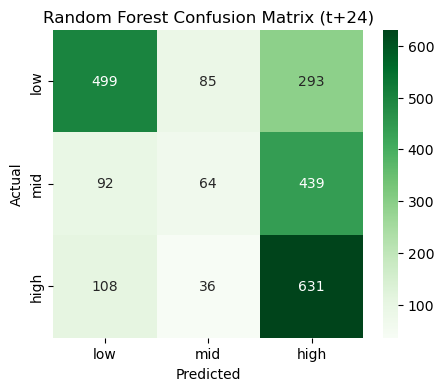

              precision    recall  f1-score   support

         low       0.71      0.57      0.63       877
         mid       0.35      0.11      0.16       595
        high       0.46      0.81      0.59       775

    accuracy                           0.53      2247
   macro avg       0.51      0.50      0.46      2247
weighted avg       0.53      0.53      0.49      2247



In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

horizons = [1, 6, 12, 24]

print("----------- RANDOM FOREST CLASSIFICATION RESULTS -----------")

for h in horizons:
    print(f"\n>>> CO Classification (t+{h})\n")

    # ----------- 1. Feature matrices -----------
    X_train = train_scaled
    X_test  = test_scaled


    # ----------- 2. Targets -----------
    y_train = train[f"CO_class_t+{h}"]
    y_test  = test[f"CO_class_t+{h}"]


    # ----------- 3. Random Forest Classifier -----------
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=4,
        min_samples_leaf=2,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )


    # ----------- 4. Train -----------
    model.fit(X_train, y_train)


    # ----------- 5. Predict -----------
    pred = model.predict(X_test)


    # ----------- 6. Accuracy -----------
    acc = accuracy_score(y_test, pred)
    print(f"Accuracy (t+{h}): {acc:.4f}")


    # ----------- 7. Confusion Matrix -----------
    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
                xticklabels=["low", "mid", "high"],
                yticklabels=["low", "mid", "high"])
    plt.title(f"Random Forest Confusion Matrix (t+{h})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # ----------- 8. Classification Report -----------
    print(classification_report(
        y_test, pred,
        target_names=["low", "mid", "high"]
    ))
